# Task 0 — Setup and Simulation

## T0.1 Environment Setup

I installed the package and tested the environment. The environment is successfully configured, and all selected tests passed.

Result: 104 passed, 10 deselected in 17.27s

## T0.2 Time Testing

**Question:** How does simulation time scale with the number of events, physics preset, and computing device?

We compare the runtime for different event counts and simulation settings.


**Data generation (PowerShell):**
```powershell
foreach ($device in @("cpu", "cuda")) {
    foreach ($n in @(10000, 100000, 200000, 1000000)) {
        foreach ($p in @("straight", "full")) {
            $prefix = if ($device -eq "cuda") {"t0_gpu_"} else {"t0_"}
            flashsim generate --preset $p -n $n --seed 3 --device $device -o "data/${prefix}${p}_n${n}.h5" --overwrite
        }
    }
}
```

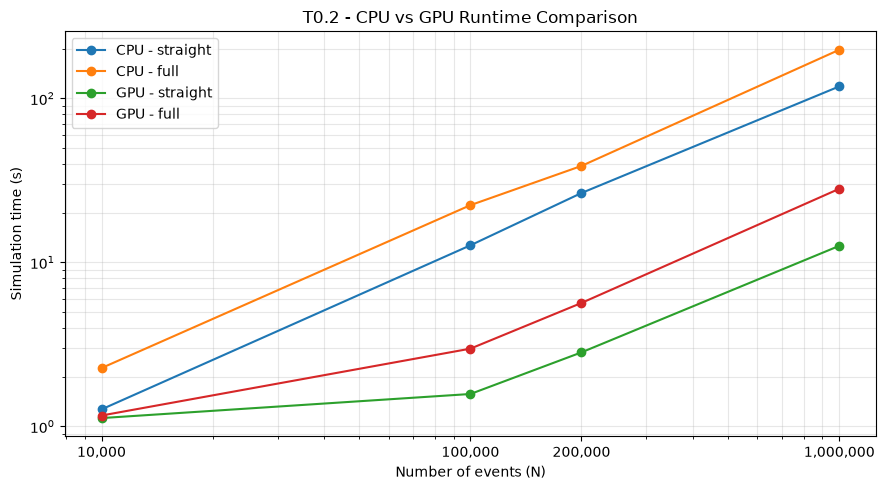

In [3]:
from pathlib import Path
import json
import h5py
import matplotlib.pyplot as plt

#Set file paths and event counts
root = Path(".") if Path("TASKS.md").exists() else Path("..")
N = [10000, 100000, 200000, 1000000]

plt.figure(figsize=(9, 5))

#Read CPU and GPU runtime data
for device, prefix in [("CPU", "t0_"), ("GPU", "t0_gpu_")]:
    for preset in ["straight", "full"]:
        times = []
        for n in N:
            file = root / "data" / f"{prefix}{preset}_n{n}.h5"
            with h5py.File(file, "r") as f:
                info = json.loads(f.attrs["provenance"])
            times.append(info["wall_time_s"])
        plt.plot(N, times, marker="o", label=f"{device} - {preset}")

# Plot settings
plt.xscale("log")
plt.yscale("log")
plt.xticks(N, ["10,000", "100,000", "200,000", "1,000,000"])

plt.xlabel("Number of events (N)")
plt.ylabel("Simulation time (s)")
plt.title("T0.2 - CPU vs GPU Runtime Comparison")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()

plt.savefig(root / "notebooks" / "T0.2_simulation_time.png", dpi=300)
plt.show()

**Observation:**

Simulation time increases approximately linearly with $N$. The `full` preset is slower than `straight`.

For $N=1{,}000{,}000$ with the `full` preset, GPU runtime is 28.113 s compared with 198.022 s on CPU, giving approximately a 7× speedup.



## T0.3 Data Structure

**Question:** Which datasets and shapes are stored in the HDF5 file, and what configuration was used?

We inspect the generated dataset using `flashsim info` to understand its structure and simulation settings.


**Command:** `flashsim info data/flash_full_n10000_seed1.h5`

**Datasets and Shapes:**
* `truth/*`, `photons/*`: (10000,)
* `response/*`: (10000, 32)
* `detector/*`: (32,)

**Configuration:** `full` preset, seed = 1, CPU, 32 sensors. Configuration and provenance are stored as metadata.

**Photon Statistics:** 32.46% detected, 51.85% absorbed in bulk, 15.69% absorbed by walls.


**Main datasets:**
- `truth`: event_id, x, y, energy, t0
- `response`: charge, time_first, time_mean
- `detector`: sensor_x, sensor_y, sensor_phi
- `photons`: n_emitted, n_detected, n_absorbed_bulk, etc.